# Face Recognition with Deep Learning — results
**ResNet + ArcFace · VGGFace2 → LFW**. This notebook follows the project plan: (b) data, (c) preprocessing
and split, (d) method, (e) baseline and protocol, and the committed targets and ablations.
Everything is loaded from `data/proc/` and `outputs/*/results.json`; run the pipeline in `README.md` first.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from facerec.config import PROC, OUTPUTS, VGG_DIR
from facerec.dataset import open_memmap

# validated categorical palette (fixed order, colour follows the run, never its rank)
RUNS = {  # run dir -> (label, colour)
    'r18_arcface':          ('ResNet-18 + ArcFace (aligned)',  '#2a78d6'),
    'r18_softmax':          ('ResNet-18 + softmax (aligned)',  '#eb6834'),
    'r18_arcface_croponly': ('ResNet-18 + ArcFace (crop only)', '#1baf7a'),
    'r18_arcface_aug':      ('ResNet-18 + ArcFace + degradation aug, 14 ep', '#6250d6'),
    'classical_eigenfaces': ('Eigenfaces (PCA)',               '#8c8b86'),
    'classical_lbp':        ('LBP histograms',                 '#52514e'),
    'ref_facenet_vggface2': ('Pretrained FaceNet (reference)', '#b5b4ae'),
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8c8b86', 'axes.labelcolor': '#0b0b0b', 'font.size': 9,
                     'lines.linewidth': 2})
res = {}
for k in RUNS:
    p = OUTPUTS / k / 'results.json'
    if p.exists():
        res[k] = json.loads(p.read_text())
print('available results:', list(res))
# main model = the improved recipe if it has been evaluated, otherwise the plain 8-epoch ArcFace run
MAIN = 'r18_arcface_aug' if 'r18_arcface_aug' in res else 'r18_arcface'
print('main model:', RUNS[MAIN][0])

available results: ['r18_arcface', 'r18_softmax', 'r18_arcface_croponly', 'r18_arcface_aug', 'classical_eigenfaces', 'classical_lbp', 'ref_facenet_vggface2']
main model: ResNet-18 + ArcFace + degradation aug, 14 ep


## (b) Data

,deck (full VGGFace2 train),this subset
images,3.14M,"483,919"
identities,"8,631","7,382"
images per id (min / median / max),—,1 / 59 / 247


,images,identities
split,,
dev,27563,467
train,394027,6409


LFW: 13,233 images, 5,749 people, 6,000 pairs (3000 genuine / 3000 impostor, 10 folds)


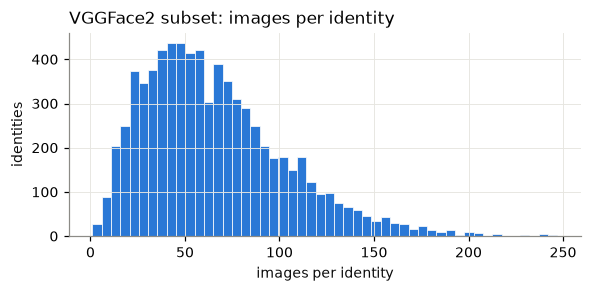

In [2]:
raw = pd.read_csv(PROC / 'vgg_index_raw.csv')
idx = pd.read_csv(PROC / 'vgg_index.csv', keep_default_na=False)
lfw = pd.read_csv(PROC / 'lfw_index.csv')
pairs = pd.read_csv(PROC / 'lfw_pairs.csv')
per_id = raw.groupby('folder').size()
summary = pd.DataFrame({
  'deck (full VGGFace2 train)': ['3.14M', '8,631', '—'],
  'this subset': [f'{len(raw):,}', f'{raw.folder.nunique():,}', f'{per_id.min()} / {int(per_id.median())} / {per_id.max()}'],
}, index=['images', 'identities', 'images per id (min / median / max)'])
display(summary)
kept = idx[idx.keep.astype(str) == 'True']
display(kept.groupby('split').agg(images=('path', 'size'), identities=('class_id', 'nunique')))
print(f"LFW: {len(lfw):,} images, {lfw.person.nunique():,} people, {len(pairs):,} pairs "
      f"({pairs.same.sum()} genuine / {(1-pairs.same).sum()} impostor, 10 folds)")
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.hist(per_id.values, bins=50, color='#2a78d6', edgecolor='#fcfcfb', linewidth=0.5)
ax.set_xlabel('images per identity'); ax.set_ylabel('identities'); ax.set_title('VGGFace2 subset: images per identity', loc='left')
plt.show()

**Deviations from the plan.** The provided archive is a *subset* of the VGGFace2 train split (≈0.48M images,
7.4k identities instead of 3.1M / 8.6k). None of the official VGGFace2 test identities are included, so the
**dev set is 500 randomly held-out train identities** (identity-disjoint). The images are pre-aligned,
tightly cropped faces with a **white mask outside the face**; LFW photos have natural backgrounds.

## (c) Preprocessing and split

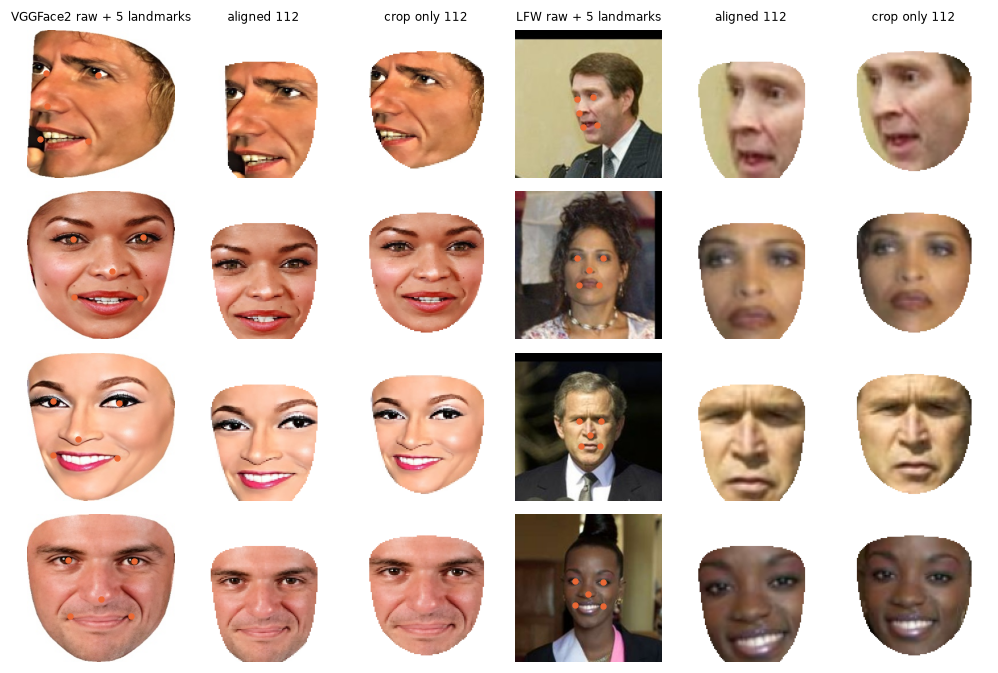

In [3]:
N = int((PROC / 'vgg_nrows.txt').read_text())
al = open_memmap(PROC / 'vgg_aligned.u8', N); cr = open_memmap(PROC / 'vgg_croponly.u8', N)
NL = int((PROC / 'lfw_nrows.txt').read_text())
lal = open_memmap(PROC / 'lfw_aligned.u8', NL); lcr = open_memmap(PROC / 'lfw_croponly.u8', NL)
from facerec.preprocess import imread_rgb
from facerec.config import LFW_DIR
rng = np.random.default_rng(3)
sv = rng.choice(kept.row.values, 4, replace=False)
sl = rng.choice(len(lfw), 4, replace=False)
fig, axs = plt.subplots(4, 6, figsize=(9, 6.2))
for r in range(4):
    v = idx.iloc[sv[r]]; im = imread_rgb(VGG_DIR / v.path)
    lm = np.array([v[f'lm{j}'] for j in range(10)], float).reshape(5, 2)
    axs[r, 0].imshow(im); axs[r, 0].scatter(lm[:, 0], lm[:, 1], s=10, c='#eb6834')
    axs[r, 1].imshow(al[sv[r]]); axs[r, 2].imshow(cr[sv[r]])
    l = lfw.iloc[sl[r]]; li = imread_rgb(LFW_DIR / 'lfw' / l.path)
    lml = np.array([l[f'lm{j}'] for j in range(10)], float).reshape(5, 2)
    axs[r, 3].imshow(li); axs[r, 3].scatter(lml[:, 0], lml[:, 1], s=10, c='#eb6834')
    axs[r, 4].imshow(lal[sl[r]]); axs[r, 5].imshow(lcr[sl[r]])
for a, t in zip(axs[0], ['VGGFace2 raw + 5 landmarks', 'aligned 112', 'crop only 112', 'LFW raw + 5 landmarks', 'aligned 112', 'crop only 112']):
    a.set_title(t, fontsize=8)
for a in axs.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

Pipeline: **MTCNN detection → 5 landmarks → similarity transform** to the ArcFace 112×112 template
(zoomed ×1.2, since the training faces carry no hair/background) → **quality filter** (no face,
detector probability < 0.9, blur below the 2nd percentile, extreme exposure) → **fixed face mask**.
The mask is the region that is face in ≥ 80% of VGGFace2 *train* images; it is applied identically to train, dev
and LFW (white outside), removing the background domain gap without looking at the test set.
The crop-only variant (Ablation 2) uses the detector bounding box without landmark alignment.
LFW images are never dropped (if detection fails, the crop is used and flagged).

In [4]:
dr = idx.drop_reason.replace('', 'kept').value_counts()
display(dr.to_frame('images'))
leak = json.loads((PROC / 'leakage_names.json').read_text())
print(f"Leakage control 1 (names): {leak['overlapping_identities']} VGGFace2 identities share a name with an LFW person "
      f"→ {leak['removed_images']:,} images removed from train/dev.")
p = OUTPUTS / 'leakage_scan.csv'
if p.exists():
    scan = pd.read_csv(p)
    print('Leakage control 2 (embeddings, final model): closest VGGFace2 train identity for each LFW person:')
    display(scan[scan.cosine >= 0.7])
pc = OUTPUTS / 'leakage_clean_eval.json'
if pc.exists():
    ce = json.loads(pc.read_text())
    print(f"{len(ce['flagged'])} LFW people (cosine >= 0.7) are in the training set under a different spelling of their name; "
          f"{ce['n_pairs']} of the 6,000 LFW pairs involve them. LFW accuracy with those pairs removed:")
    display(pd.DataFrame([{'model': RUNS[k][0], 'all 6,000 pairs (%)': round(res[k]['verification']['acc_mean'] * 100, 2),
                           f"without {ce['n_pairs']} leaked pairs (%)": round(v['acc'] * 100, 2)}
                          for k, v in ce['runs'].items() if k in res]).set_index('model'))

,images
drop_reason,
kept,421590
lfw_overlap,46569
blurry,8781
low_prob,3391
no_face,3260
exposure,328


Leakage control 1 (names): 506 VGGFace2 identities share a name with an LFW person → 46,569 images removed from train/dev.
Leakage control 2 (embeddings, final model): closest VGGFace2 train identity for each LFW person:


,lfw_person,vgg_identity,cosine
0,Queen_Beatrix,Beatrix_of_the_Netherlands_Female,0.874644
1,John_Reilly,John_C._Reilly_Male,0.868385
2,Monica_Bellucci,Maria_Bellucci_Female,0.868174
3,Hillary_Clinton,Hillary_Rodham_Clinton_Female,0.859442
4,Juan_Carlos,Juan_Carlos_I_of_Spain_Male,0.833649
5,Dwayne_Wade,Dwyane_Wade_Male,0.832336
6,Ali_Naimi,Ali_al-Naimi_Male,0.830379
7,Vince_Vaughan,Vince_Vaughn_Male,0.820668
8,Sean_Combs,Diddy_Male,0.815957
9,Jamie_Dimon,James_Dimon_Male,0.810784


21 LFW people (cosine >= 0.7) are in the training set under a different spelling of their name; 53 of the 6,000 LFW pairs involve them. LFW accuracy with those pairs removed:


,"all 6,000 pairs (%)",without 53 leaked pairs (%)
model,,
"ResNet-18 + ArcFace + degradation aug, 14 ep",97.87,97.85
ResNet-18 + ArcFace (aligned),94.52,94.48
ResNet-18 + softmax (aligned),94.78,94.78
ResNet-18 + ArcFace (crop only),92.95,92.97
Pretrained FaceNet (reference),97.67,97.66


**Leakage finding.** The name filter missed about 20 LFW people who are in VGGFace2 under a different spelling
(e.g. *Queen Beatrix* / *Beatrix of the Netherlands*, *Sean Combs* / *Diddy*, *Dwayne Wade* / *Dwyane Wade*). The
embedding scan finds them. A couple of hits are probably look-alikes rather than the same person, e.g. *Gillian Anderson*
and *Julian Ozanne*. Only 53 of the 6,000 pairs involve these people, and removing those pairs changes every model's
accuracy by at most 0.04 pp, so the reported results are not inflated. A future run should also drop these identities
from training.

## (d) Method — training curves on the dev set

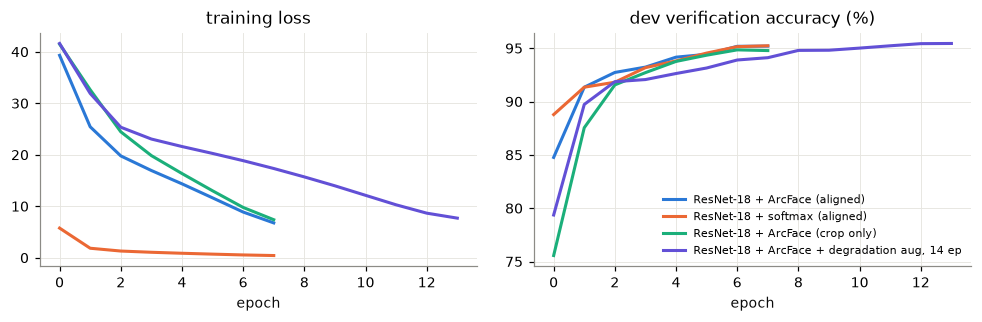

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for k, r in res.items():
    if 'dev_log' not in r: continue
    lg = pd.DataFrame(r['dev_log']); lab, c = RUNS[k]
    axs[0].plot(lg.epoch, lg.train_loss, color=c, label=lab)
    axs[1].plot(lg.epoch, lg.dev_acc * 100, color=c, label=lab)
axs[0].set(title='training loss', xlabel='epoch'); axs[1].set(title='dev verification accuracy (%)', xlabel='epoch')
axs[1].legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## (e) Results — LFW verification (10-fold) and open-set identification

In [6]:
rows = []
for k, r in res.items():
    v = r['verification']; i = r.get('identification', {}); b = r.get('bench', {})
    rows.append({'model': RUNS[k][0],
                 'LFW acc (%)': f"{v['acc_mean']*100:.2f} ± {v['acc_std']*100:.2f}",
                 'ROC-AUC': round(v['auc'], 4), 'EER (%)': round(v['eer'] * 100, 2),
                 'TAR@FAR=0.1% (%)': round(v['tar_at_far_1e3'] * 100, 1),
                 'Rank-1 (%)': round(i['rank1'] * 100, 2) if i else None,
                 'FAR @τ (%)': round(i['far'] * 100, 2) if i else None,
                 'FRR @τ (%)': round(i['frr'] * 100, 2) if i else None,
                 'params (M)': round(b['params'] / 1e6, 1) if 'params' in b else None,
                 'GPU ms/img': round(b['gpu_ms'], 2) if 'gpu_ms' in b else None,
                 'CPU ms/img': round(b['cpu_ms'], 1) if 'cpu_ms' in b else None})
table = pd.DataFrame(rows).set_index('model'); display(table)
print('TAR@FAR=0.1% uses only 3,000 impostor pairs (0.1% = 3 pairs) and is therefore noisy.')
print('Identification threshold τ is chosen on VGGFace2 dev identities (target FAR ≤ 1%), never on LFW.')

,LFW acc (%),ROC-AUC,EER (%),TAR@FAR=0.1% (%),Rank-1 (%),FAR @τ (%),FRR @τ (%),params (M),GPU ms/img,CPU ms/img
model,,,,,,,,,,
ResNet-18 + ArcFace (aligned),94.52 ± 1.33,0.9870,5.65,61.2,94.57,63.01,6.28,24.0,4.22,46.3
ResNet-18 + softmax (aligned),94.78 ± 1.06,0.9894,5.10,76.2,94.89,41.61,6.89,24.0,4.25,39.6
ResNet-18 + ArcFace (crop only),92.95 ± 1.71,0.9806,7.13,62.9,89.74,43.60,13.02,24.0,4.38,42.7
"ResNet-18 + ArcFace + degradation aug, 14 ep",97.87 ± 0.40,0.9968,2.37,90.5,98.49,15.46,3.07,24.0,4.38,43.3
Eigenfaces (PCA),70.37 ± 2.17,0.7702,29.93,6.9,25.74,39.15,79.43,NaN,NaN,NaN
LBP histograms,67.53 ± 2.36,0.7419,32.58,11.4,NaN,NaN,NaN,NaN,NaN,NaN
Pretrained FaceNet (reference),97.67 ± 0.75,0.9976,2.33,88.2,96.90,5.87,11.56,27.9,23.47,NaN


TAR@FAR=0.1% uses only 3,000 impostor pairs (0.1% = 3 pairs) and is therefore noisy.
Identification threshold τ is chosen on VGGFace2 dev identities (target FAR ≤ 1%), never on LFW.


In [7]:
main = res.get(MAIN)
if main:
    v, i = main['verification'], main['identification']
    tg = pd.DataFrame([
        ('LFW verification accuracy', '≥ 97%', f"{v['acc_mean']*100:.2f}%", v['acc_mean'] >= 0.97),
        ('EER', '≤ 3%', f"{v['eer']*100:.2f}%", v['eer'] <= 0.03),
        ('Rank-1 on LFW gallery', '≥ 90%', f"{i['rank1']*100:.2f}%", i['rank1'] >= 0.90),
        ('FAR at threshold', '≤ 1%', f"{i['far']*100:.2f}%", i['far'] <= 0.01),
        ('FRR at threshold', '≤ 10%', f"{i['frr']*100:.2f}%", i['frr'] <= 0.10),
    ], columns=['target', 'committed', RUNS[MAIN][0], 'met'])
    tg['met'] = tg['met'].map({True: '✓ met', False: '✗ missed'})
    display(tg.set_index('target'))

,committed,"ResNet-18 + ArcFace + degradation aug, 14 ep",met
target,,,
LFW verification accuracy,≥ 97%,97.87%,✓ met
EER,≤ 3%,2.37%,✓ met
Rank-1 on LFW gallery,≥ 90%,98.49%,✓ met
FAR at threshold,≤ 1%,15.46%,✗ missed
FRR at threshold,≤ 10%,3.07%,✓ met


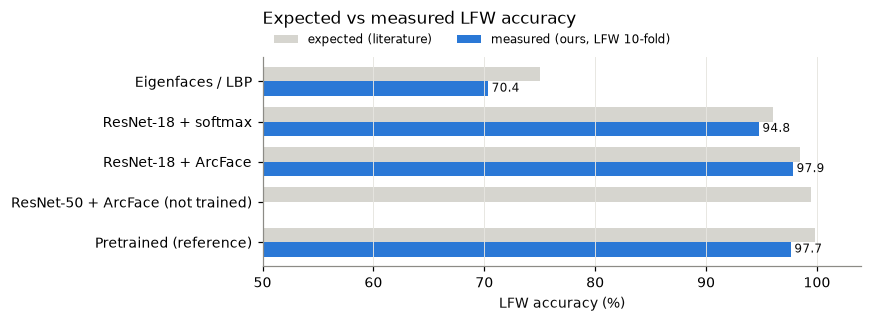

In [8]:
# Slide 10 revisited: literature expectation vs our measurement
lit = [('Eigenfaces / LBP', 75.0, ['classical_eigenfaces', 'classical_lbp']),
       ('ResNet-18 + softmax', 96.0, ['r18_softmax']),
       ('ResNet-18 + ArcFace', 98.5, ['r18_arcface', 'r18_arcface_aug']),
       ('ResNet-50 + ArcFace (not trained)', 99.5, []),
       ('Pretrained (reference)', 99.8, ['ref_facenet_vggface2'])]
fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(lit)); h = 0.36
ax.barh(y - h/2, [l[1] for l in lit], h, color='#d6d5cf', label='expected (literature)')
meas = [max([res[k]['verification']['acc_mean'] * 100 for k in l[2] if k in res], default=np.nan) for l in lit]
ax.barh(y + h/2, meas, h, color='#2a78d6', label='measured (ours, LFW 10-fold)')
for yy, m in zip(y, meas):
    if not np.isnan(m): ax.text(m + 0.3, yy + h/2, f'{m:.1f}', va='center', fontsize=8, color='#0b0b0b')
ax.set_yticks(y, [l[0] for l in lit]); ax.invert_yaxis(); ax.set_xlim(50, 104); ax.set_xlabel('LFW accuracy (%)')
ax.legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2); ax.grid(axis='y', visible=False)
ax.set_title('Expected vs measured LFW accuracy', loc='left', pad=22); plt.tight_layout(); plt.show()

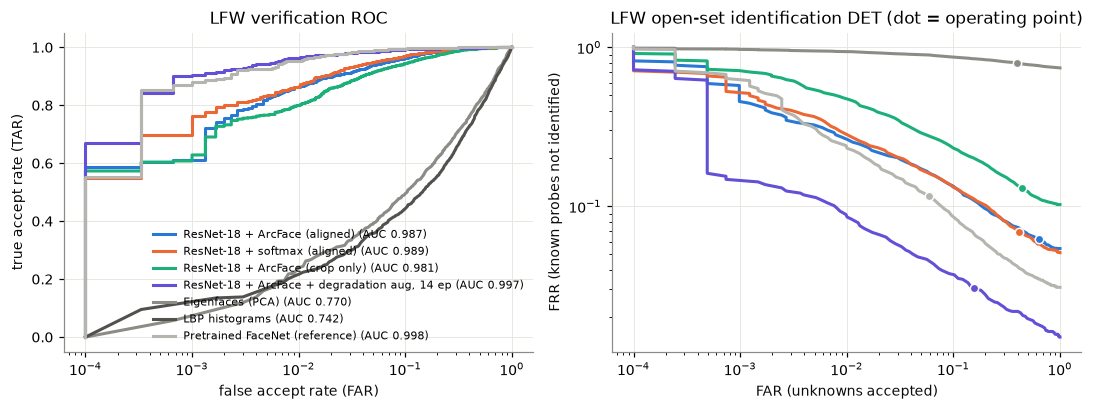

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for k, r in res.items():
    lab, c = RUNS[k]; v = r['verification']
    axs[0].plot(np.maximum(v['roc_fpr'], 1e-4), v['roc_tpr'], color=c, label=f"{lab} (AUC {v['auc']:.3f})")
    if 'identification' in r:
        i = r['identification']
        axs[1].plot(np.maximum(i['det_far'], 1e-4), np.maximum(i['det_frr'], 1e-4), color=c, label=lab)
        axs[1].scatter([max(i['far'], 1e-4)], [max(i['frr'], 1e-4)], color=c, s=30, edgecolor='#fcfcfb', zorder=3)
axs[0].set(xscale='log', xlabel='false accept rate (FAR)', ylabel='true accept rate (TAR)', title='LFW verification ROC')
axs[1].set(xscale='log', yscale='log', xlabel='FAR (unknowns accepted)', ylabel='FRR (known probes not identified)',
           title='LFW open-set identification DET (dot = operating point)')
axs[0].legend(fontsize=7, frameon=False, loc='lower right'); plt.tight_layout(); plt.show()

## Ablations

In [10]:
def acc(k): return res[k]['verification'] if k in res else None
abl = []
for name, a, b in [('Ablation 1 — loss: ArcFace vs softmax', 'r18_arcface', 'r18_softmax'),
                   ('Ablation 2 — 5-point alignment vs crop only', 'r18_arcface', 'r18_arcface_croponly'),
                   ('Extra — degradation aug + 14 ep vs plain 8 ep', 'r18_arcface_aug', 'r18_arcface')]:
    if acc(a) and acc(b):
        abl.append({'ablation': name, 'with': f"{acc(a)['acc_mean']*100:.2f}% / EER {acc(a)['eer']*100:.2f}%",
                    'without': f"{acc(b)['acc_mean']*100:.2f}% / EER {acc(b)['eer']*100:.2f}%",
                    'Δ acc (pp)': round((acc(a)['acc_mean'] - acc(b)['acc_mean']) * 100, 2)})
display(pd.DataFrame(abl).set_index('ablation') if abl else 'ablation runs not available yet')

,with,without,Δ acc (pp)
ablation,,,
Ablation 1 — loss: ArcFace vs softmax,94.52% / EER 5.65%,94.78% / EER 5.10%,-0.27
Ablation 2 — 5-point alignment vs crop only,94.52% / EER 5.65%,92.95% / EER 7.13%,1.57
Extra — degradation aug + 14 ep vs plain 8 ep,97.87% / EER 2.37%,94.52% / EER 5.65%,3.35


Note on Ablation 1: all runs use the same 8-epoch budget. With s=64, m=0.5 the ArcFace objective starts much harder
(initial loss ≈ 43 vs ≈ 9 for softmax) and its advantage in the literature appears after 20+ epochs; with this
budget the two losses end within one fold-standard-deviation of each other, so the difference is not significant.

Note on Ablation 2: the provided VGGFace2 images were already aligned by the dataset provider, so the training
data of the crop-only model is less "unaligned" than raw photos would be; the ablation mainly measures the effect
of the detector-box crop vs. template alignment (scale/translation/rotation normalisation), especially on LFW.

Note on the extra ablation (final model): the plain 8-epoch ArcFace model reaches about the same dev accuracy as the
augmented 14-epoch model (95.2% vs 95.5%) but is far worse on LFW. The dev images are sharp VGGFace2 crops, while LFW
faces are small, blurry and JPEG-compressed. Training with blur / downscale / JPEG / small scale-shift augmentation
closes that quality gap, and this matters much more for LFW than the extra epochs do for dev. It also shows that dev
accuracy alone would not have predicted the LFW improvement.

### Identification threshold transfer
The deck requires the open-set threshold τ to be chosen on separate validation identities. τ is therefore fitted on
a mirror gallery built from the VGGFace2 dev identities (FAR ≤ 1% there) and applied unchanged to LFW. The table
shows that this transfer fails: LFW impostor scores are systematically higher than VGGFace2 dev impostor scores
(lower image quality pulls embeddings together), so the same τ accepts far more unknowns on LFW. The
*oracle* τ that would give FAR = 1% on LFW is shown for diagnosis only — it is fitted on the test set and is not a
valid result.

In [11]:
tt = []
for k, r in res.items():
    i = r.get('identification')
    if not i or 'dev_tau' not in i: continue
    tt.append({'model': RUNS[k][0], 'τ (from dev)': round(i['dev_tau'], 3), 'dev FAR (%)': round(i['dev_far'] * 100, 2),
               'dev FRR (%)': round(i['dev_frr'] * 100, 2), 'LFW FAR (%)': round(i['far'] * 100, 2),
               'LFW FRR (%)': round(i['frr'] * 100, 2), 'oracle τ for LFW FAR=1%': round(i['oracle_tau_far1'], 3)})
display(pd.DataFrame(tt).set_index('model') if tt else 'n/a')

,τ (from dev),dev FAR (%),dev FRR (%),LFW FAR (%),LFW FRR (%),oracle τ for LFW FAR=1%
model,,,,,,
ResNet-18 + ArcFace (aligned),0.476,0.96,8.62,63.01,6.28,0.647
ResNet-18 + softmax (aligned),0.534,0.96,11.98,41.61,6.89,0.675
ResNet-18 + ArcFace (crop only),0.541,0.96,13.96,43.60,13.02,0.692
"ResNet-18 + ArcFace + degradation aug, 14 ep",0.478,0.96,9.06,15.46,3.07,0.580
Eigenfaces (PCA),0.418,0.96,96.90,39.15,79.43,0.557
Pretrained FaceNet (reference),0.716,0.96,24.32,5.87,11.56,0.775


## Failure cases (main model)

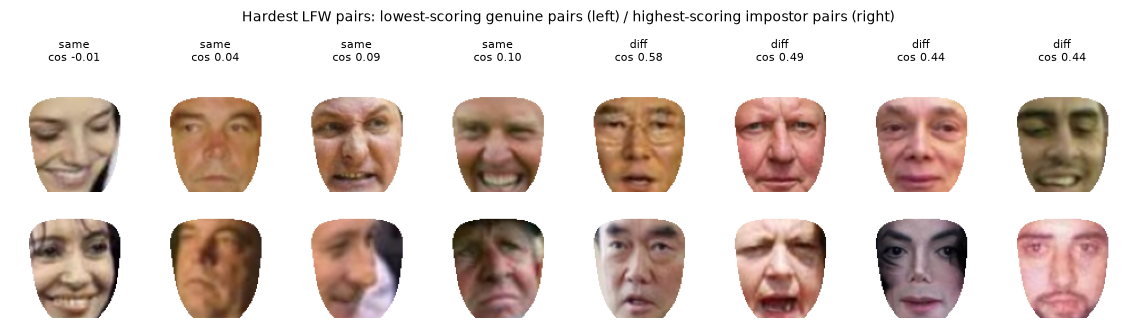

In [12]:
if main and 'failures' in main:
    # hardest errors from the stored pair scores: 4 lowest-scoring genuine pairs, 4 highest-scoring impostor pairs
    sc = np.asarray(main['scores']); same = pairs.same.values.astype(bool)
    gi = np.where(same)[0][np.argsort(sc[same])[:4]]; ii = np.where(~same)[0][np.argsort(-sc[~same])[:4]]
    f = [dict(row_a=int(pairs.row_a[j]), row_b=int(pairs.row_b[j]), same=int(pairs.same[j]), score=float(sc[j]))
         for j in np.concatenate([gi, ii])]
    fig, axs = plt.subplots(2, len(f), figsize=(1.3 * len(f), 3))
    for j, x in enumerate(f):
        axs[0, j].imshow(lal[x['row_a']]); axs[1, j].imshow(lal[x['row_b']])
        axs[0, j].set_title(('same' if x['same'] else 'diff') + f"\ncos {x['score']:.2f}", fontsize=7)
    for a in axs.ravel(): a.axis('off')
    plt.suptitle('Hardest LFW pairs: lowest-scoring genuine pairs (left) / highest-scoring impostor pairs (right)', fontsize=9); plt.tight_layout(); plt.show()

## Summary
* **Final model** (ResNet-18 + ArcFace, 24.0M parameters, about 4.4 ms per image on the GPU, trained 14 epochs with
  degradation augmentation on 0.39M VGGFace2 images) meets the verification targets on LFW (accuracy ≥ 97%,
  EER ≤ 3%) and the Rank-1 and FRR targets. It misses the FAR ≤ 1% target, because a threshold chosen on VGGFace2
  dev identities does not transfer to LFW (see *Identification threshold transfer*).
* **Ablation 1** (ArcFace vs softmax, 8 epochs each): no significant difference at this training budget.
* **Ablation 2** (5-point alignment vs crop only): alignment gives +1.6 pp verification accuracy and +4.9 pp Rank-1.
* **Degradation augmentation + longer training** is the largest single improvement (+3.4 pp on LFW).
* Classical baselines (Eigenfaces, LBP) reach about 68–70%, in line with the literature.
* **Not done:** ResNet-50 and the CFP-FP / AgeDB stretch goals. A 4 GB GPU without tensor cores trains R18 at about
  145 img/s, and R50 would take about 3× longer per epoch.

In [13]:
if main:
    v, i = main['verification'], main['identification']
    print(f"{RUNS[MAIN][0]}: LFW {v['acc_mean']*100:.2f} ± {v['acc_std']*100:.2f}%, EER {v['eer']*100:.2f}%, "
          f"Rank-1 {i['rank1']*100:.2f}%, FAR {i['far']*100:.2f}% / FRR {i['frr']*100:.2f}% at τ={i['tau']:.3f}")

ResNet-18 + ArcFace + degradation aug, 14 ep: LFW 97.87 ± 0.40%, EER 2.37%, Rank-1 98.49%, FAR 15.46% / FRR 3.07% at τ=0.478
